# Uplift Modeling for Personalized Marketing in Telecommunications
**Applied Machine Learning — Final Project**<br>
**Students:** Abilkhay Askar, Kolzhabay Olzhas<br>
**Group:** Big Data Analysis 2406

## README — how to run this project
**Goal.** Decide which telecom subscribers should receive a marketing offer so that *incremental* conversions are maximised. For every customer the notebook estimates the uplift `uplift(x) = P(Y=1 | X=x, T=1) − P(Y=1 | X=x, T=0)` and ranks customers by it.

**Requirements.** Python ≥ 3.9 with `numpy`, `pandas`, `scikit-learn`, `matplotlib` and `scikit-uplift` (`sklift`). Google Colab already has everything except `scikit-uplift`, which the first code cell installs automatically.

**Data.** MegaFon Uplift Competition dataset (600,000 labelled rows, 50 anonymised features). The loader cell reads `data/megafon_dataset.csv.gz` (run `python scripts/download_data.py` from the repository root) or `megafon_dataset.csv.gz` next to the notebook; otherwise it downloads the same file with `sklift.datasets.fetch_megafon()` (~270 MB, a few minutes on Colab).

**Steps to reproduce.**
1. Open the notebook in Google Colab (or Jupyter) and choose *Runtime → Run all*.
2. All random seeds are fixed (`SEED = 42`, repeated splits use seeds 42, 7, 123, 2024, 99). Results are identical on every run on the same library versions.
3. The full pipeline (loading → tuning → evaluation → targeting list) took 14 minutes on a 2-core machine (allow 20–30 minutes on free Colab); the last cell prints the measured runtime.

**Outputs.** Figures are written to the repository's `figures/` folder, tables to `results/`, and the final targeting list to `results/targeting_list_top30.csv.gz` (customer id, predicted uplift, rank, `target` flag). In Colab both folders are created next to the notebook.

**Notebook structure.** 1 Setup → 2 Load & validate → 3 Treatment/control → 4 Group balance → 5 Train/test split → 6 Hyper-parameter tuning by cross-validated Qini → 7 Models & evaluation → 8 Repeated splits & model selection → 9 Decile analysis → 10 Campaign efficiency → 11 Targeting list → 12 Negative-uplift profile → 13 Feature influence (permutation importance) → 14 Success-criteria check.

## 1. Setup
Install `scikit-uplift` if it is missing, import libraries, fix random seeds and define project-wide settings.

In [1]:
import sys, subprocess, importlib.util
if importlib.util.find_spec("sklift") is None:          # Colab: install scikit-uplift once
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "scikit-uplift"])

import os, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn, sklift
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklift.models import SoloModel, TwoModels, ClassTransformation
from sklift.metrics import (qini_auc_score, uplift_auc_score, uplift_at_k,
                            qini_curve, uplift_by_percentile)

warnings.filterwarnings("ignore", category=FutureWarning)
T0 = time.time()
SEED = 42
SEEDS = [42, 7, 123, 2024, 99]      # repeated train/test splits
TEST_SIZE = 0.30
K = 0.30                            # campaign contact share
from pathlib import Path
# repo layout: notebooks/ sits next to data/, figures/ and results/; in Colab everything goes to the current folder
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR, RES_DIR = ROOT / "figures", ROOT / "results"
FIG_DIR.mkdir(exist_ok=True); RES_DIR.mkdir(exist_ok=True)

# consistent figure style
COLORS = {"S-learner": "#2a78d6", "T-learner": "#eb6834", "Class transformation": "#1baf7a",
          "T-learner (LogReg)": "#eda100", "Conversion model": "#e87ba4", "Random": "#8a8984"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "font.size": 10, "axes.titleweight": "bold"})
print(f"python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | scikit-uplift {sklift.__version__} | matplotlib {matplotlib.__version__}")

python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | scikit-uplift 0.5.1 | matplotlib 3.11.2


## 2. Load and validate the data (Requirement 3.1-1)
The file contains the treatment flag, 50 anonymised numeric features `X_1 … X_50` and the binary `conversion` outcome. The distributed file has no explicit subscriber id column, so the row index is used as `customer_id`.

In [2]:
CANDIDATES = [ROOT / "data" / "megafon_dataset.csv.gz", Path("megafon_dataset.csv.gz")]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is not None:
    df = pd.read_csv(DATA_PATH)
else:
    from sklift.datasets import fetch_megafon
    b = fetch_megafon()
    df = pd.concat([b.data, b.treatment, b.target], axis=1)
df.insert(0, "customer_id", np.arange(len(df)))

FEATURES = [f"X_{i}" for i in range(1, 51)]
print("Shape (rows, columns):", df.shape)
print("Feature columns:", len(FEATURES))
print("Missing values (total):", int(df.isna().sum().sum()))
print("Duplicate rows (excluding id):", int(df.drop(columns="customer_id").duplicated().sum()))
print("Column types:", df.dtypes.astype(str).value_counts().to_dict())
display(df[["customer_id", "treatment_group"] + FEATURES[:6] + ["X_50", "conversion"]].head().round(3))
display(df[FEATURES[:8]].describe().T.round(3))

Shape (rows, columns): (600000, 53)
Feature columns: 50
Missing values (total): 0
Duplicate rows (excluding id): 0
Column types: {'float64': 50, 'int64': 2, 'str': 1}


,customer_id,treatment_group,X_1,X_2,X_3,X_4,X_5,X_6,X_50,conversion
0,0,control,39.397,-0.187,19.525,21.250,55.291,182.967,16.231,0
1,1,control,38.988,0.820,-42.065,-48.271,-33.171,179.459,10.732,0
2,2,treatment,-16.693,1.845,-8.615,-18.819,-22.271,-116.290,14.368,0
3,3,treatment,-72.040,-0.227,39.803,16.441,-1.113,68.128,11.634,0
4,4,treatment,18.297,0.996,24.465,-34.152,24.623,-155.456,-11.884,0


,count,mean,std,min,25%,50%,75%,max
X_1,600000.0,-3.759,54.882,-271.659,-40.693,-3.955,33.175,250.812
X_2,600000.0,0.000,0.999,-4.372,-0.673,0.001,0.673,5.062
X_3,600000.0,0.356,31.804,-148.871,-20.758,0.373,21.496,170.053
X_4,600000.0,-1.004,45.291,-244.447,-30.645,-0.585,29.028,235.096
X_5,600000.0,3.377,53.398,-302.574,-31.865,3.721,38.989,284.916
X_6,600000.0,-6.396,140.874,-683.126,-100.762,-6.357,88.160,656.482
X_7,600000.0,-2.254,59.810,-322.732,-42.314,-2.264,37.710,293.910
X_8,600000.0,-6.433,74.841,-506.203,-54.841,-6.416,41.963,550.526


## 3. Treatment and control groups (Requirement 3.1-2)
`T = 1` for customers who received the offer, `T = 0` for the control group. The difference in conversion rates is the average treatment effect (ATE) of the campaign.

,n,conversions,conversion_rate,share
treatment_group,,,,
control,299632,53754,0.1794,0.4994
treatment,300368,68760,0.2289,0.5006


Average treatment effect (ATE) = 0.0495  (95% CI 0.0475 to 0.0516)
Relative lift = 27.6%


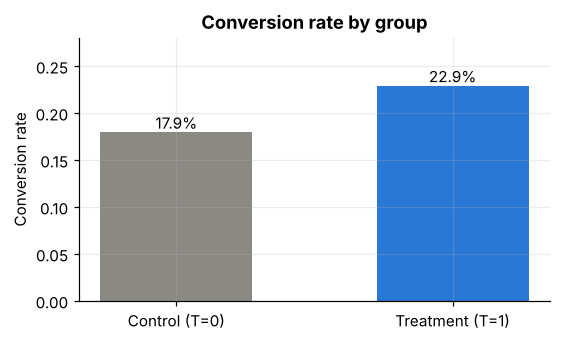

In [3]:
df["T"] = (df["treatment_group"] == "treatment").astype(int)
X, y, t = df[FEATURES], df["conversion"].astype(int), df["T"]
assert set(df["treatment_group"].unique()) == {"treatment", "control"}

grp = df.groupby("treatment_group")["conversion"].agg(n="size", conversions="sum", conversion_rate="mean")
grp["share"] = grp["n"] / len(df)
display(grp.round(4))

p1, p0 = y[t == 1].mean(), y[t == 0].mean()
n1, n0 = (t == 1).sum(), (t == 0).sum()
ate = p1 - p0
se = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
print(f"Average treatment effect (ATE) = {ate:.4f}  (95% CI {ate - 1.96*se:.4f} to {ate + 1.96*se:.4f})")
print(f"Relative lift = {ate / p0:.1%}")

fig, ax = plt.subplots(figsize=(5.2, 3.2))
bars = ax.bar(["Control (T=0)", "Treatment (T=1)"], [p0, p1], color=["#8a8984", "#2a78d6"], width=0.55)
for b_, v in zip(bars, [p0, p1]):
    ax.text(b_.get_x() + b_.get_width() / 2, v + 0.004, f"{v:.1%}", ha="center")
ax.set_ylabel("Conversion rate"); ax.set_ylim(0, 0.28)
ax.set_title("Conversion rate by group")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig1_group_conversion.png"); plt.show()

## 4. Group balance check (Requirement 3.1-3)
If the offer was assigned at random, every feature should have almost the same distribution in both groups. We use the standardised mean difference
`SMD = (mean_T − mean_C) / sqrt((var_T + var_C) / 2)` with the usual threshold |SMD| < 0.1.

Max |SMD| = 0.0046 (X_27)
Features with |SMD| >= 0.1: 0


,|SMD|
X_27,0.0046
X_5,0.0045
X_44,0.0044
X_9,0.0036
X_28,0.0036


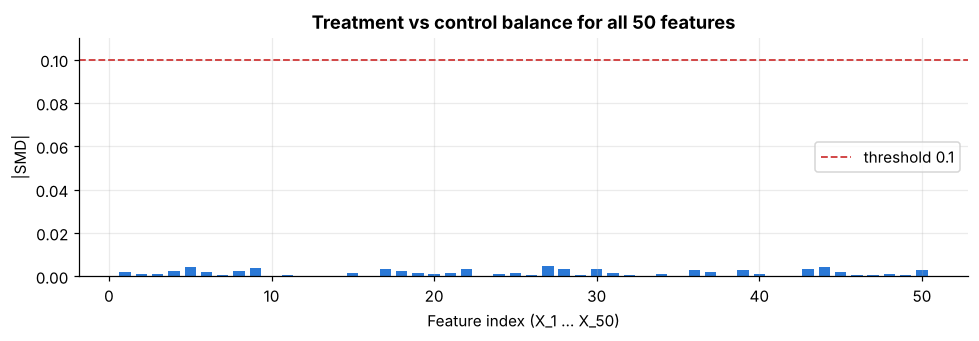

In [4]:
mt, mc = X[t == 1].mean(), X[t == 0].mean()
vt, vc = X[t == 1].var(), X[t == 0].var()
smd = ((mt - mc) / np.sqrt((vt + vc) / 2)).rename("SMD")
print(f"Max |SMD| = {smd.abs().max():.4f} ({smd.abs().idxmax()})")
print("Features with |SMD| >= 0.1:", int((smd.abs() >= 0.1).sum()))
display(smd.abs().sort_values(ascending=False).head(5).to_frame("|SMD|").round(4))

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(range(1, 51), smd.abs().values, color="#2a78d6", width=0.7)
ax.axhline(0.1, color="#d03b3b", ls="--", lw=1.2, label="threshold 0.1")
ax.set_xlabel("Feature index (X_1 … X_50)"); ax.set_ylabel("|SMD|")
ax.set_title("Treatment vs control balance for all 50 features"); ax.set_ylim(0, 0.11); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "fig2_balance_smd.png"); plt.show()

## 5. Train/test split (Requirement 3.1-4)
30 % of the rows are held out. The split is stratified on the four combinations of treatment and conversion, so both proportions are preserved. The test set is never used for training or tuning.

In [5]:
def split(seed):
    strata = t * 2 + y
    return train_test_split(np.arange(len(df)), test_size=TEST_SIZE, stratify=strata, random_state=seed)

idx_tr, idx_te = split(SEED)
X_tr, X_te = X.iloc[idx_tr], X.iloc[idx_te]
y_tr, y_te = y.iloc[idx_tr], y.iloc[idx_te]
t_tr, t_te = t.iloc[idx_tr], t.iloc[idx_te]

split_tab = pd.DataFrame({
    "rows": [len(df), len(idx_tr), len(idx_te)],
    "treatment_share": [t.mean(), t_tr.mean(), t_te.mean()],
    "conversion_rate": [y.mean(), y_tr.mean(), y_te.mean()],
    "observed_uplift": [ate, y_tr[t_tr == 1].mean() - y_tr[t_tr == 0].mean(),
                        y_te[t_te == 1].mean() - y_te[t_te == 0].mean()]},
    index=["full", "train", "test"])
display(split_tab.round(4))
print("Max deviation of treatment share from full data (pp):",
      round(100 * max(abs(t_tr.mean() - t.mean()), abs(t_te.mean() - t.mean())), 4))

,rows,treatment_share,conversion_rate,observed_uplift
full,600000,0.5006,0.2042,0.0495
train,420000,0.5006,0.2042,0.0495
test,180000,0.5006,0.2042,0.0495


Max deviation of treatment share from full data (pp): 0.0002


## 6. Model definitions and hyper-parameter tuning by cross-validated Qini (Nice-to-have 3.2-2)
**Approaches**
* **S-learner** (`SoloModel`): one classifier on `[X, T]`; uplift = f(x, 1) − f(x, 0).
* **T-learner** (`TwoModels`, vanilla): one classifier on the treated rows and one on the control rows; uplift = f₁(x) − f₀(x).
* **Class transformation** (`ClassTransformation`): new label Z = 1 if (T=1, Y=1) or (T=0, Y=0); with a 50/50 treatment split, uplift = 2·P(Z=1|x) − 1.
* **T-learner (LogReg)**: the same T-learner with standardised logistic regression, a linear reference.
* **Baselines**: random scores, and a conventional *conversion model* (the same gradient-boosting classifier trained on X only, ranking customers by P(Y=1|x)).

**Base learner.** `HistGradientBoostingClassifier` (histogram gradient-boosted trees). Settings are chosen by the mean 3-fold cross-validated Qini coefficient **on the training set only** — not by accuracy.

In [6]:
def hgb(lr=0.1, leaves=31, iters=200):
    return HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=leaves, max_iter=iters,
                                          min_samples_leaf=100, l2_regularization=1.0,
                                          early_stopping=False, random_state=SEED)

def make_model(name, params):
    if name == "S-learner":
        return SoloModel(estimator=hgb(**params), method="dummy")
    if name == "T-learner":
        return TwoModels(estimator_trmnt=hgb(**params), estimator_ctrl=hgb(**params), method="vanilla")
    if name == "Class transformation":
        return ClassTransformation(estimator=hgb(**params))
    if name == "T-learner (LogReg)":
        lr_ = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
        return TwoModels(estimator_trmnt=lr_(), estimator_ctrl=lr_(), method="vanilla")
    raise ValueError(name)

FITTED = {}   # fitted models from the main split (filled in Section 7)

def fit_score(name, params, Xa, ya, ta, Xb, keep=False):
    """Fit an uplift model (or a baseline) on (Xa, ya, ta) and return uplift-ranking scores for Xb."""
    if name == "Random":
        return np.random.RandomState(SEED).rand(len(Xb))
    if name == "Conversion model":
        return hgb(**params).fit(Xa, ya).predict_proba(Xb)[:, 1]
    model = make_model(name, params).fit(Xa, ya, ta)
    scores = model.predict(Xb)
    if keep:
        FITTED[name] = model
    return scores

GRID = [dict(lr=0.1, leaves=31, iters=200), dict(lr=0.05, leaves=31, iters=300),
        dict(lr=0.1, leaves=15, iters=200), dict(lr=0.1, leaves=63, iters=150)]
TUNED = ["S-learner", "T-learner", "Class transformation"]

t_start = time.time()
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
cv_rows = []
for name in TUNED:
    for gi, params in enumerate(GRID):
        scores = []
        for f_tr, f_va in skf.split(X_tr, t_tr * 2 + y_tr):
            u = fit_score(name, params, X_tr.iloc[f_tr], y_tr.iloc[f_tr], t_tr.iloc[f_tr], X_tr.iloc[f_va])
            scores.append(qini_auc_score(y_tr.iloc[f_va], u, t_tr.iloc[f_va]))
        cv_rows.append({"model": name, "config": gi, **params,
                        "cv_qini_mean": np.mean(scores), "cv_qini_std": np.std(scores)})
cv = pd.DataFrame(cv_rows)
display(cv.round(4))
BEST = {m: GRID[int(cv[cv.model == m].sort_values("cv_qini_mean").iloc[-1]["config"])] for m in TUNED}
BEST["Conversion model"] = BEST["S-learner"]
for m in TUNED:
    print(f"{m:22s} selected config: {BEST[m]}")
print(f"Tuning time: {(time.time() - t_start) / 60:.1f} min")
cv.to_csv(RES_DIR / "cv_tuning.csv", index=False)

,model,config,lr,leaves,iters,cv_qini_mean,cv_qini_std
0,S-learner,0,0.10,31,200,0.2313,0.0012
1,S-learner,1,0.05,31,300,0.2310,0.0015
2,S-learner,2,0.10,15,200,0.2179,0.0020
3,S-learner,3,0.10,63,150,0.2365,0.0007
4,T-learner,0,0.10,31,200,0.2364,0.0015
5,T-learner,1,0.05,31,300,0.2361,0.0024
6,T-learner,2,0.10,15,200,0.2292,0.0015
7,T-learner,3,0.10,63,150,0.2380,0.0003
8,Class transformation,0,0.10,31,200,0.2184,0.0025
9,Class transformation,1,0.05,31,300,0.2233,0.0033


S-learner              selected config: {'lr': 0.1, 'leaves': 63, 'iters': 150}
T-learner              selected config: {'lr': 0.1, 'leaves': 63, 'iters': 150}
Class transformation   selected config: {'lr': 0.05, 'leaves': 31, 'iters': 300}
Tuning time: 9.6 min


## 7. Estimate uplift and evaluate on the held-out test set (Requirements 3.1-5, 3.1-6; Nice-to-have 3.2-1, 3.2-3)
Metrics (all from `sklift.metrics`, computed on the 180,000 test customers):
* **Qini coefficient** – area between the model's Qini curve and the random line, normalised by the perfect model (random = 0, perfect = 1).
* **AUUC** – the same normalisation applied to the uplift curve.
* **Uplift@30 %** – treatment conversion rate minus control conversion rate among the 30 % of customers with the highest scores.

In [7]:
MODELS = ["S-learner", "T-learner", "Class transformation", "T-learner (LogReg)", "Conversion model", "Random"]
scores_te, fit_time = {}, {}
for name in MODELS:
    s0 = time.time()
    scores_te[name] = fit_score(name, BEST.get(name, GRID[0]), X_tr, y_tr, t_tr, X_te, keep=True)
    fit_time[name] = time.time() - s0

overall_uplift_te = y_te[t_te == 1].mean() - y_te[t_te == 0].mean()
res = pd.DataFrame({
    "Qini coefficient": {m: qini_auc_score(y_te, s, t_te) for m, s in scores_te.items()},
    "AUUC": {m: uplift_auc_score(y_te, s, t_te) for m, s in scores_te.items()},
    "Uplift@30%": {m: uplift_at_k(y_te, s, t_te, strategy="overall", k=K) for m, s in scores_te.items()},
    "Fit+predict time (s)": fit_time}).loc[MODELS]
print(f"Observed uplift on the whole test set: {overall_uplift_te:.4f}")
display(res.round(4))
res.to_csv(RES_DIR / "test_metrics.csv")

Observed uplift on the whole test set: 0.0495


,Qini coefficient,AUUC,Uplift@30%,Fit+predict time (s)
S-learner,0.2430,0.1679,0.2193,11.9013
T-learner,0.2450,0.1695,0.2244,13.5178
Class transformation,0.2315,0.1599,0.2165,14.6379
T-learner (LogReg),0.0405,0.0282,0.0852,2.0673
Conversion model,0.0965,0.0666,0.1153,10.7173
Random,-0.0033,-0.0023,0.0454,0.0011


**Qini curves.** Each curve shows the cumulative number of incremental conversions when customers are contacted in the order given by the model. The dashed diagonal is random targeting.

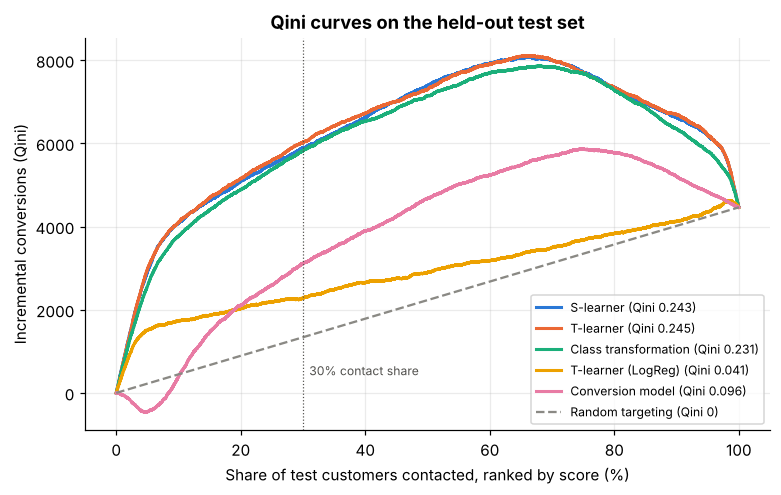

In [8]:
fig, ax = plt.subplots(figsize=(7.2, 4.6))
for name in MODELS:
    if name == "Random":
        continue
    xs, ys = qini_curve(y_te, scores_te[name], t_te)
    ax.plot(xs / len(y_te) * 100, ys, lw=2, color=COLORS[name],
            label=f"{name} (Qini {res.loc[name, 'Qini coefficient']:.3f})")
ax.plot([0, 100], [0, ys[-1]], ls="--", color=COLORS["Random"], lw=1.5, label="Random targeting (Qini 0)")
ax.axvline(30, color="#52514e", lw=0.8, ls=":")
ax.text(31, ax.get_ylim()[1] * 0.05, "30% contact share", color="#52514e", fontsize=8)
ax.set_xlabel("Share of test customers contacted, ranked by score (%)")
ax.set_ylabel("Incremental conversions (Qini)")
ax.set_title("Qini curves on the held-out test set")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig3_qini_curves.png"); plt.show()

# save the curves at 2% steps for the presentation
grid_pct = np.arange(0, 101, 2)
curve_tab = {"share_pct": grid_pct}
for name in MODELS[:-1]:
    xs, ys = qini_curve(y_te, scores_te[name], t_te)
    curve_tab[name] = np.interp(grid_pct, xs / len(y_te) * 100, ys)
curve_tab["Random"] = grid_pct / 100 * ys[-1]
pd.DataFrame(curve_tab).to_csv(RES_DIR / "qini_curves.csv", index=False)

## 8. Stability over five repeated train/test splits and final model selection (Success criterion 7)
Every approach is re-trained on five different stratified 70/30 splits (with the tuned settings). The final model is the approach with the **highest mean Qini coefficient**.

,qini_mean,qini_std,qini_min,positive_splits,uplift30_mean
model,,,,,
S-learner,0.2407,0.0046,0.2330,5,0.2186
T-learner,0.2438,0.0026,0.2405,5,0.2227
Class transformation,0.2304,0.0027,0.2264,5,0.2145
T-learner (LogReg),0.0356,0.0030,0.0332,5,0.0811
Conversion model,0.0958,0.0026,0.0919,5,0.1153
Random,-0.0021,0.0034,-0.0073,1,0.0479


Repeated-split time: 4.5 min
Selected final model: T-learner


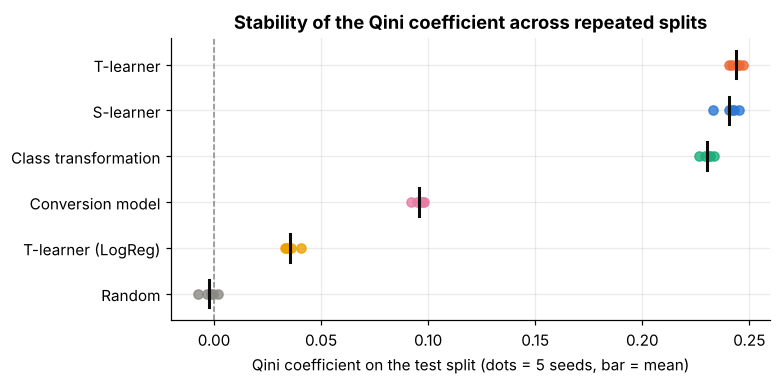

In [9]:
rep_rows = []
t_start = time.time()
for sd in SEEDS:
    a, b_ = split(sd)
    for name in MODELS:
        u = fit_score(name, BEST.get(name, GRID[0]), X.iloc[a], y.iloc[a], t.iloc[a], X.iloc[b_])
        rep_rows.append({"seed": sd, "model": name,
                         "qini": qini_auc_score(y.iloc[b_], u, t.iloc[b_]),
                         "uplift_at_30": uplift_at_k(y.iloc[b_], u, t.iloc[b_], strategy="overall", k=K)})
rep = pd.DataFrame(rep_rows)
summary = rep.groupby("model").agg(qini_mean=("qini", "mean"), qini_std=("qini", "std"),
                                   qini_min=("qini", "min"), positive_splits=("qini", lambda s: int((s > 0).sum())),
                                   uplift30_mean=("uplift_at_30", "mean")).loc[MODELS]
display(summary.round(4))
rep.to_csv(RES_DIR / "repeated_splits.csv", index=False)
print(f"Repeated-split time: {(time.time() - t_start) / 60:.1f} min")

FINAL = summary.drop(["Random", "Conversion model"])["qini_mean"].idxmax()
print("Selected final model:", FINAL)

fig, ax = plt.subplots(figsize=(7.2, 3.6))
order = summary.sort_values("qini_mean").index
for i, name in enumerate(order):
    vals = rep[rep.model == name]["qini"].values
    ax.scatter(vals, [i] * len(vals), color=COLORS[name], s=36, alpha=0.8, zorder=3)
    ax.plot([vals.mean()] * 2, [i - 0.3, i + 0.3], color="#0b0b0b", lw=2, zorder=4)
ax.axvline(0, color="#8a8984", ls="--", lw=1)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.set_xlabel("Qini coefficient on the test split (dots = 5 seeds, bar = mean)")
ax.set_title("Stability of the Qini coefficient across repeated splits")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig4_repeated_splits.png"); plt.show()

## 9. Observed conversion rates by decile of predicted uplift (Nice-to-have 3.2-3)
Test customers are sorted by the final model's score and cut into ten equal groups. In each decile we report the *observed* treatment and control conversion rates; their difference is the observed uplift. A good model shows high observed uplift in the first deciles and low or negative uplift in the last ones.

,n_treatment,n_control,response_rate_treatment,response_rate_control,uplift
D1,8917,9083,0.5967,0.1367,0.4600
D2,8946,9054,0.2362,0.1190,0.1172
D3,8994,9006,0.2145,0.1168,0.0977
D4,9059,8941,0.2006,0.1238,0.0768
D5,8961,9039,0.1861,0.1218,0.0643
D6,9130,8870,0.2018,0.1347,0.0670
D7,9027,8973,0.1764,0.1669,0.0094
D8,9038,8962,0.0897,0.1631,-0.0734
D9,9019,8981,0.0993,0.1708,-0.0715
D10,9019,8981,0.2926,0.5409,-0.2483


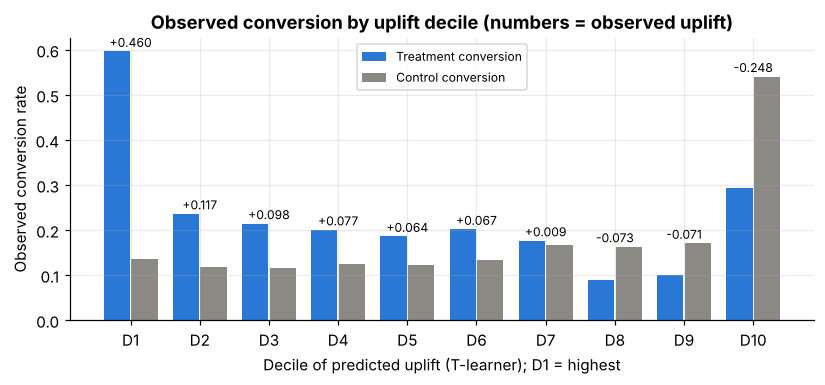

In [10]:
u_final = scores_te[FINAL]
dec = uplift_by_percentile(y_te, u_final, t_te, strategy="overall", bins=10, total=False)
dec.index = [f"D{i}" for i in range(1, 11)]
display(dec.round(4))
dec.to_csv(RES_DIR / "deciles_final_model.csv")

fig, ax = plt.subplots(figsize=(7.6, 3.6))
xi = np.arange(10)
ax.bar(xi - 0.2, dec["response_rate_treatment"], 0.38, color="#2a78d6", label="Treatment conversion")
ax.bar(xi + 0.2, dec["response_rate_control"], 0.38, color="#8a8984", label="Control conversion")
ax2_vals = dec["uplift"].values
for i, v in enumerate(ax2_vals):
    ax.text(i, max(dec["response_rate_treatment"].iloc[i], dec["response_rate_control"].iloc[i]) + 0.01,
            f"{v:+.3f}", ha="center", fontsize=8)
ax.set_xticks(xi); ax.set_xticklabels(dec.index)
ax.set_xlabel(f"Decile of predicted uplift ({FINAL}); D1 = highest")
ax.set_ylabel("Observed conversion rate"); ax.legend(fontsize=8)
ax.set_title("Observed conversion by uplift decile (numbers = observed uplift)")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig5_deciles.png"); plt.show()

## 10. Campaign efficiency for different contact shares (Nice-to-have 3.2-4)
Incremental conversions in a contacted group of size n are estimated as n × (treatment rate − control rate) observed in that group. Random targeting of the same n customers is expected to give n × (overall test uplift).

,customers_contacted,random_targeting,T-learner,Conversion model,gain_vs_random (T-learner)
contact_share,,,,,
10%,18000,891.4,8279.8,782.7,9.3
20%,36000,1782.8,10379.1,4204.0,5.8
30%,54000,2674.3,12119.2,6224.0,4.5
40%,72000,3565.7,13477.1,7799.3,3.8
50%,90000,4457.1,14638.8,9371.9,3.3


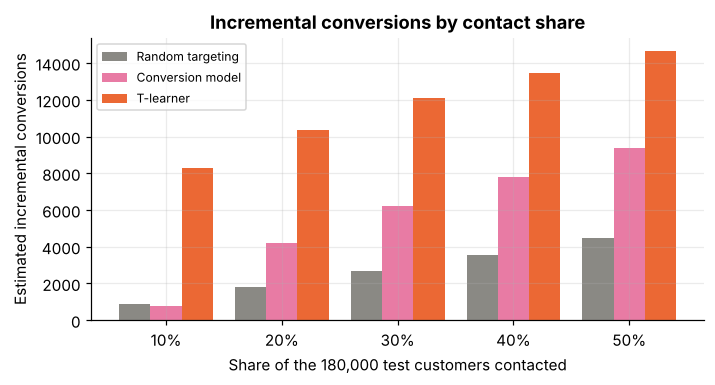

In [11]:
eff_rows = []
for k in [0.1, 0.2, 0.3, 0.4, 0.5]:
    n_sel = int(round(k * len(y_te)))
    row = {"contact_share": f"{int(k*100)}%", "customers_contacted": n_sel,
           "random_targeting": n_sel * overall_uplift_te}
    for name in [FINAL, "Conversion model"]:
        row[name] = n_sel * uplift_at_k(y_te, scores_te[name], t_te, strategy="overall", k=k)
    eff_rows.append(row)
eff = pd.DataFrame(eff_rows).set_index("contact_share")
eff[f"gain_vs_random ({FINAL})"] = eff[FINAL] / eff["random_targeting"]
display(eff.round(1))
eff.to_csv(RES_DIR / "campaign_efficiency.csv")

fig, ax = plt.subplots(figsize=(6.6, 3.6))
xi = np.arange(len(eff)); w = 0.27
ax.bar(xi - w, eff["random_targeting"], w, color=COLORS["Random"], label="Random targeting")
ax.bar(xi, eff["Conversion model"], w, color=COLORS["Conversion model"], label="Conversion model")
ax.bar(xi + w, eff[FINAL], w, color=COLORS[FINAL], label=FINAL)
ax.set_xticks(xi); ax.set_xticklabels(eff.index)
ax.set_xlabel("Share of the 180,000 test customers contacted")
ax.set_ylabel("Estimated incremental conversions"); ax.legend(fontsize=8)
ax.set_title("Incremental conversions by contact share")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig6_campaign_efficiency.png"); plt.show()

## 11. Targeting list (Requirement 3.1-7)
All test customers are ranked by the final model's predicted uplift; the top 30 % are marked `target`. For the S- and T-learner the two potential-outcome probabilities are also reported, which reproduces the input/output examples from the proposal.

In [12]:
out = pd.DataFrame({"customer_id": df["customer_id"].iloc[idx_te].values, "predicted_uplift": u_final})
if FINAL in ("S-learner", "T-learner"):
    mdl = FITTED[FINAL]
    mdl.predict(X_te)                      # refreshes the stored per-arm probabilities for the test set
    out["p_with_offer"] = mdl.trmnt_preds_
    out["p_without_offer"] = mdl.ctrl_preds_
out = out.sort_values("predicted_uplift", ascending=False).reset_index(drop=True)
out["rank"] = np.arange(1, len(out) + 1)
n_target = int(round(K * len(out)))
out["decision"] = np.where(out["rank"] <= n_target, "target", "do not target")
out.to_csv(RES_DIR / "targeting_list_top30.csv.gz", index=False)
print(f"Customers ranked: {len(out):,}; marked 'target': {n_target:,} ({K:.0%})")
print(f"Missing or infinite scores: {int((~np.isfinite(out['predicted_uplift'])).sum())}")
display(out.head(5).round(4))
display(out.iloc[[n_target - 1, n_target, len(out) - 1]].round(4))

Customers ranked: 180,000; marked 'target': 54,000 (30%)
Missing or infinite scores: 0


,customer_id,predicted_uplift,p_with_offer,p_without_offer,rank,decision
0,435517,0.8340,0.9004,0.0664,1,target
1,512292,0.8324,0.9124,0.0799,2,target
2,361952,0.8315,0.8917,0.0602,3,target
3,536669,0.8249,0.9009,0.0760,4,target
4,246842,0.8246,0.9290,0.1044,5,target


,customer_id,predicted_uplift,p_with_offer,p_without_offer,rank,decision
53999,492666,0.1098,0.2087,0.0989,54000,target
54000,379866,0.1098,0.2053,0.0954,54001,do not target
179999,519801,-0.9117,0.0489,0.9606,180000,do not target


## 12. Profile of customers with negative predicted uplift (Nice-to-have 3.2-5)
Customers whose predicted uplift is below zero are compared with the rest. Because the features are anonymised, differences are reported only as standardised mean differences, without business interpretation.

In [13]:
neg = u_final < 0
print(f"Share of test customers with negative predicted uplift: {neg.mean():.2%}")
yt, tt = y_te.values, t_te.values
obs_uplift = {}
for lbl, m in [("negative group", neg), ("rest", ~neg)]:
    obs_uplift[lbl] = yt[m & (tt == 1)].mean() - yt[m & (tt == 0)].mean()
    print(f"Observed uplift in {lbl:14s}: {obs_uplift[lbl]:+.4f} (n = {m.sum():,})")
Xn, Xr = X_te[neg], X_te[~neg]
smd_neg = ((Xn.mean() - Xr.mean()) / np.sqrt((Xn.var() + Xr.var()) / 2)).rename("SMD (negative vs rest)")
top_neg = smd_neg.reindex(smd_neg.abs().sort_values(ascending=False).index).head(8)
display(top_neg.to_frame().round(3))

Share of test customers with negative predicted uplift: 35.15%
Observed uplift in negative group: -0.1146 (n = 63,279)
Observed uplift in rest          : +0.1385 (n = 116,721)


,SMD (negative vs rest)
X_4,0.104
X_42,0.065
X_33,0.049
X_49,-0.040
X_38,0.033
X_17,-0.029
X_15,-0.027
X_48,-0.027


## 13. Feature influence on the uplift estimates (Nice-to-have 3.2-6)
**Permutation importance on the Qini coefficient.** On a 60,000-customer sample of the test set, each feature is shuffled in turn (two repeats) and the final model's uplift is re-predicted. The drop in the Qini coefficient measures how much the ranking quality depends on that feature. This uses the fitted model directly, so no surrogate approximation is needed.

Baseline Qini on the sample: 0.2365
Features whose permutation lowers Qini by > 0.005: 18 of 50
Top-10 features account for 73.9% of the total positive drop


,Qini drop
X_16,0.0558
X_5,0.0371
X_4,0.0359
X_22,0.0348
X_40,0.0309
X_35,0.0257
X_41,0.0186
X_29,0.0181
X_8,0.0164
X_33,0.0157


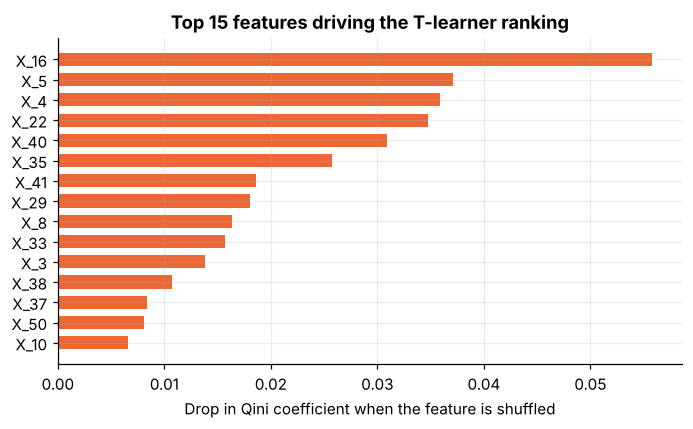

In [14]:
rs = np.random.RandomState(SEED)
sample = rs.choice(len(X_te), 60000, replace=False)
Xs, ys_, ts_ = X_te.iloc[sample].reset_index(drop=True), y_te.iloc[sample].values, t_te.iloc[sample].values
model_final = FITTED[FINAL]
base_q = qini_auc_score(ys_, model_final.predict(Xs), ts_)
drops = {}
for f in FEATURES:
    d = []
    for r in range(2):
        Xp = Xs.copy()
        Xp[f] = np.random.RandomState(SEED + r).permutation(Xp[f].values)
        d.append(base_q - qini_auc_score(ys_, model_final.predict(Xp), ts_))
    drops[f] = np.mean(d)
imp = pd.Series(drops).sort_values(ascending=False)
print(f"Baseline Qini on the sample: {base_q:.4f}")
print(f"Features whose permutation lowers Qini by > 0.005: {int((imp > 0.005).sum())} of 50")
print(f"Top-10 features account for {imp.clip(lower=0).head(10).sum() / imp.clip(lower=0).sum():.1%} of the total positive drop")
display(imp.head(10).to_frame("Qini drop").round(4))
imp.to_csv(RES_DIR / "feature_influence.csv", header=["qini_drop"])

fig, ax = plt.subplots(figsize=(6.4, 4.0))
top = imp.head(15)[::-1]
ax.barh(top.index, top.values, color="#eb6834", height=0.65)
ax.set_xlabel("Drop in Qini coefficient when the feature is shuffled")
ax.set_title(f"Top 15 features driving the {FINAL} ranking")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig7_feature_influence.png"); plt.show()

## 14. Success-criteria check (Proposal §4)

In [15]:
elapsed_min = (time.time() - T0) / 60
fin = summary.loc[FINAL]
top30_uplift = res.loc[FINAL, "Uplift@30%"]
crit = [
    ("1 Data size", f"{len(df):,} rows used, {len(idx_te):,} held out", len(df) >= 100_000),
    ("2 Group identification", f"max treatment-share deviation {100*max(abs(t_tr.mean()-t.mean()), abs(t_te.mean()-t.mean())):.3f} pp",
     df["T"].isin([0, 1]).all() and max(abs(t_tr.mean()-t.mean()), abs(t_te.mean()-t.mean())) <= 0.01),
    ("3 Group balance", f"max |SMD| = {smd.abs().max():.4f}", smd.abs().max() < 0.1),
    ("4 Coverage", f"{np.isfinite(u_final).sum():,} of {len(u_final):,} scores finite", np.isfinite(u_final).all()),
    ("5 Better than random", f"Qini = {res.loc[FINAL, 'Qini coefficient']:.4f}", res.loc[FINAL, "Qini coefficient"] > 0),
    ("6 Better than conversion model", f"{res.loc[FINAL, 'Qini coefficient']:.4f} vs {res.loc['Conversion model', 'Qini coefficient']:.4f}",
     res.loc[FINAL, "Qini coefficient"] > res.loc["Conversion model", "Qini coefficient"]),
    ("7 Stability", f"positive Qini in {int(fin['positive_splits'])} of 5 splits", fin["positive_splits"] >= 4),
    ("8 Targeting value", f"uplift@30% {top30_uplift:.4f} vs overall {overall_uplift_te:.4f}", top30_uplift > overall_uplift_te),
    ("9 Reproducibility", f"end-to-end runtime {elapsed_min:.1f} min, fixed seeds", elapsed_min < 60),
]
crit_df = pd.DataFrame(crit, columns=["criterion", "measured value", "met"]).set_index("criterion")
display(crit_df)
json.dump({"final_model": FINAL, "best_params": {k: v for k, v in BEST.items()},
           "ate": ate, "ate_ci": [ate - 1.96*se, ate + 1.96*se], "overall_uplift_test": overall_uplift_te,
           "max_smd": float(smd.abs().max()), "neg_share": float(neg.mean()), "perm_base_qini": base_q, "obs_uplift_neg": obs_uplift["negative group"], "obs_uplift_rest": obs_uplift["rest"],
           "top_smd_neg": {k: float(v) for k, v in top_neg.items()},
           "runtime_min": elapsed_min}, open(RES_DIR / "notebook_summary.json", "w"), indent=2, default=float)
print(f"All criteria met: {bool(crit_df['met'].all())}")
print(f"Total runtime: {elapsed_min:.1f} minutes")

,measured value,met
criterion,,
1 Data size,"600,000 rows used, 180,000 held out",True
2 Group identification,max treatment-share deviation 0.000 pp,True
3 Group balance,max |SMD| = 0.0046,True
4 Coverage,"180,000 of 180,000 scores finite",True
5 Better than random,Qini = 0.2450,True
6 Better than conversion model,0.2450 vs 0.0965,True
7 Stability,positive Qini in 5 of 5 splits,True
8 Targeting value,uplift@30% 0.2244 vs overall 0.0495,True
9 Reproducibility,"end-to-end runtime 16.1 min, fixed seeds",True


All criteria met: True
Total runtime: 16.1 minutes
